# Shape vs Position Errors

Does the model mostly get the **position** right and the **shape** wrong? Each sample's IoU is split into three parts by undoing one error at a time on the predicted mask (binarised at 0.5, 64x64):

1. `iou_raw`: as predicted.
2. `iou_main`: only the largest connected blob of the prediction is kept. The gain `iou_main - iou_raw` is the **fragment loss** (a spurious second blob somewhere else; can be negative when the dropped blob was the better one).
3. `iou_pos`: that blob is shifted so its CoM lands on the true CoM. The gain `iou_pos - iou_main` is the **position loss**.
4. `iou_size`: additionally rescaled about the CoM to the true area. The gain `iou_size - iou_pos` is the **size loss** (under- or over-painting).
5. `1 - iou_size` is what's left: the **shape loss**.

Baselines for scale:
- `gt_at_pred_com`: the *true* mask moved to the predicted CoM. This is the IoU a perfect shape model would get with the same position error.
- `disk`: a disk with the true area at the true CoM. A model that knows the position and size but nothing about shape.
- `canon`: the object's canonical shape at the true CoM, scaled to the true area. This is the CoM-aligned mean of the same (box, object) masks at *other* positions (leave-one-position-out). It is an upper bound for "classify the object and paste its usual shape".
- `boundary IoU` (d = 2 px): IoU of the 2-px bands just inside each mask's edge (Cheng et al. 2021). Raw and after position + size alignment.

The CoM shift only makes sense for one object, so sections 3-5 use single-object samples. Two-object samples get a best-shift search in section 6.

# 1 Setup

In [1]:
import json, os
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from scipy import ndimage as ndi

RUN = os.environ.get("RUN", "s6-gastro-plastic-cardboard-3k")
REPO = Path.cwd().parent
EXPERIMENTS = REPO / "experiments"
HIST = REPO / "runs" / RUN / "outputs_history"
EPOCH = max(int(f.name[2:6]) for f in (HIST / "eval").rglob("ep*.pt"))   # last saved eval epoch
D = 2               # boundary-IoU band width in output pixels
N_TRAIN = 3000      # train samples from the last epoch's saved train batches (reference only)
rng = np.random.default_rng(0)
print(RUN, "epoch", EPOCH)

s7-gpc-edge-500ep epoch 500


# 2 Load Predictions and Ground Truth

The saved outputs don't carry the sample id, so samples are matched on (experiment, position_id, speaker). The ground truth is rebuilt exactly as `src6/dataset.process_y` does it: `03_smask.png` BOX-resized to the output size.

In [2]:
def load_meta(d): return {k: v for l in (d / "metadata.jsonl").read_text().splitlines() if l.strip() for k, v in json.loads(l).items()}

def load(files, split_of):
    rows, preds = [], []
    for f in files:
        d = torch.load(f, weights_only=False)
        info = d["info"]
        for j, (e, pos, spk) in enumerate(zip(info["experiment"], info["position_id"].tolist(), info["speaker"].tolist())):
            rows.append(dict(split=split_of(f), experiment=e, position_id=pos, speaker=spk, iou_logged=float(d["metrics"]["iou"][j])))
            preds.append(d["mask_pred"][j].float().numpy())
    return pd.DataFrame(rows), np.stack(preds)

ev, P_ev = load(sorted((HIST / "eval").rglob(f"ep{EPOCH:04d}-*.pt")), lambda f: f"{f.parent.parent.name}/{f.parent.name}")
tr, P_tr = load(sorted((HIST / "train").glob(f"ep{EPOCH:04d}-*.pt")), lambda f: "train")
keep = rng.choice(len(tr), min(N_TRAIN, len(tr)), replace=False)
tr, P_tr = tr.iloc[keep].reset_index(drop=True), P_tr[keep]
df, P = pd.concat([ev, tr], ignore_index=True), np.concatenate([P_ev, P_tr])
H, W = P.shape[1:]

index = {}
for e in df.experiment.unique():
    for d in (EXPERIMENTS / e / "samples").iterdir():
        if (d / "metadata.jsonl").exists():
            m = load_meta(d); index[e, m["position_id"], m["speaker"]] = (d, m)

def gt(d): return np.clip(np.asarray(Image.open(d / "image/03_smask.png").convert("F").resize((W, H), Image.BOX), np.float32) / 255, 0, 1)
hits = [index[k] for k in zip(df.experiment, df.position_id, df.speaker)]
G = np.stack([gt(d) for d, _ in hits])
df["box"] = [m["box"] for _, m in hits]
df["object"] = ["+".join(sorted(m["objects"])) for _, m in hits]
df["n_obj"] = [m["n_objects"] for _, m in hits]
df["layout"] = [m["layout"] for _, m in hits]

# sanity: the soft IoU we recompute must match the one logged during training
soft = np.minimum(P, G).sum((1, 2)) / np.maximum(np.maximum(P, G).sum((1, 2)), 1e-6)
print("max |soft iou - logged| =", np.abs(soft - df.iou_logged).max().round(4))
print(df.groupby([df.split.eq("train").map({True: "train", False: "eval"}), "n_obj"]).size().unstack())

max |soft iou - logged| = 0.0
n_obj   0     1    2
split               
eval   12  4448  336
train  37  2629  334


# 3 Per-Sample Decomposition

All masks are binarised at 0.5. `shift` and `scale_about` use nearest-pixel resampling (linear + re-threshold makes masks of a few pixels vanish). Samples whose prediction is empty, or whose true mask is empty, are dropped from the decomposition (counted below).

In [3]:
def iou(a, b): return (a & b).sum() / max((a | b).sum(), 1)
def com(m): return np.array(ndi.center_of_mass(m.astype(float)))
def shift(m, d): return ndi.shift(m.astype(np.uint8), np.round(d), order=0, mode="constant") > 0
def scale_about(m, c, s):   # zoom by s around point c: out(x) = in(c + (x - c) / s)
    return ndi.affine_transform(m.astype(np.uint8), np.eye(2) / s, offset=c - c / s, order=0, mode="constant") > 0
def band(m, d=D): return m & ~ndi.binary_erosion(m, iterations=d, border_value=0)
def biou(a, b): return iou(band(a), band(b))
yy, xx = np.mgrid[:H, :W]
def disk(c, area): return (yy - c[0]) ** 2 + (xx - c[1]) ** 2 <= area / np.pi

Pb, Gb = P > 0.5, G > 0.5
single = (df.n_obj == 1).to_numpy()

# canonical shape per (box, object): CoM-aligned mean of every single-object mask in this table, built per position so we can leave one out
C0 = np.array([H / 2, W / 2])
centred = {}
for i in np.flatnonzero(single & Gb.any((1, 2))):
    centred.setdefault((df.box[i], df.object[i], df.position_id[i]), shift(Gb[i], C0 - com(Gb[i])).astype(float))
by_obj = defaultdict(dict)
for (b, o, pos), m in centred.items(): by_obj[b, o][pos] = m
def canon(i, c, area):
    others = [m for pos, m in by_obj[df.box[i], df.object[i]].items() if pos != df.position_id[i]]
    if not others: return None
    mean = np.mean(others, 0)
    t = np.sort(mean.ravel())[::-1][max(int(round(area)) - 1, 0)]   # threshold the mean so it has the true area
    return shift(mean >= t, c - C0)

rows = []
for i in np.flatnonzero(single):
    p, g = Pb[i], Gb[i]
    if not p.any() or not g.any(): rows.append(dict(i=i, empty_pred=not p.any())); continue
    lab, nb = ndi.label(p); main = lab == 1 + np.argmax(np.bincount(lab.ravel())[1:])
    cp, cg, ap, ag = com(main), com(g), p.sum(), g.sum()
    p_pos = shift(main, cg - cp)
    p_size = scale_about(p_pos, cg, np.sqrt(ag / max(p_pos.sum(), 1)))
    k = canon(i, cg, ag)
    rows.append(dict(i=i, empty_pred=False, n_blobs=nb, iou_raw=iou(p, g), iou_main=iou(main, g), iou_pos=iou(p_pos, g), iou_size=iou(p_size, g),
                     gt_at_pred_com=iou(shift(g, cp - cg), g), disk=iou(disk(cg, ag), g), canon=iou(k, g) if k is not None else np.nan,
                     biou_raw=biou(p, g), biou_aligned=biou(p_size, g), canon_biou=biou(k, g) if k is not None else np.nan,
                     com_err_px=np.linalg.norm(cp - cg), area_ratio=ap / ag, area_px=ag))
S = pd.DataFrame(rows).merge(df, left_on="i", right_index=True)
S["group"] = np.where(S.split == "train", "train", S.split.str.split("/").str[0])
print("single-object samples:", len(S), "| empty predictions:", int(S.empty_pred.sum()), "| by group:", S.groupby("group").empty_pred.agg(["size", "sum"]).to_dict("index"))
S = S[~S.empty_pred].copy()
S["loss_frag"], S["loss_pos"], S["loss_size"], S["loss_shape"] = S.iou_main - S.iou_raw, S.iou_pos - S.iou_main, S.iou_size - S.iou_pos, 1 - S.iou_size
S["multi_blob"] = S.n_blobs > 1

single-object samples: 7077 | empty predictions: 552 | by group: {'cardboard': {'size': 1822, 'sum': 452}, 'gastro': {'size': 884, 'sum': 54}, 'plastic': {'size': 1742, 'sum': 46}, 'train': {'size': 2629, 'sum': 0}}


# 4 Results

## 4.1 Summary by Box

In [4]:
cols = ["multi_blob", "iou_raw", "iou_main", "iou_pos", "iou_size", "gt_at_pred_com", "disk", "canon", "biou_raw", "biou_aligned", "canon_biou", "com_err_px", "area_ratio"]
summary = S.groupby("group")[cols].mean()
summary.insert(0, "n", S.groupby("group").size())
summary["area_ratio_median"] = S.groupby("group").area_ratio.median()
summary.loc["eval (all)"] = [S.group.ne("train").sum(), *S[S.group != "train"][cols].mean(), S[S.group != "train"].area_ratio.median()]
summary.round(3)

,n,multi_blob,iou_raw,iou_main,iou_pos,iou_size,gt_at_pred_com,disk,canon,biou_raw,biou_aligned,canon_biou,com_err_px,area_ratio,area_ratio_median
group,,,,,,,,,,,,,,,
cardboard,1370.0,0.018,0.431,0.431,0.641,0.739,0.499,0.723,0.850,0.250,0.549,0.716,4.692,0.819,0.860
gastro,830.0,0.022,0.561,0.562,0.728,0.802,0.610,0.783,0.856,0.393,0.680,0.761,2.082,1.196,0.968
plastic,1696.0,0.005,0.628,0.628,0.716,0.805,0.710,0.779,0.846,0.431,0.657,0.733,1.531,1.424,0.964
train,2629.0,0.000,0.980,0.980,0.980,0.980,1.000,0.744,0.867,0.961,0.961,0.756,0.058,1.006,1.000
eval (all),3896.0,0.013,0.544,0.545,0.692,0.781,0.615,0.760,0.849,0.359,0.624,0.733,2.760,1.163,0.938


## 4.2 Where the Missing IoU Goes

Each bar is 1 - IoU split into fragment / position / size / shape loss (single-object samples, mean). The black tick is where the bar would end if the shape part were only as large as the canonical-shape baseline's (`1 - canon`): the gap between the tick and the bar top is the shape error the model has *beyond* "paste the usual shape".

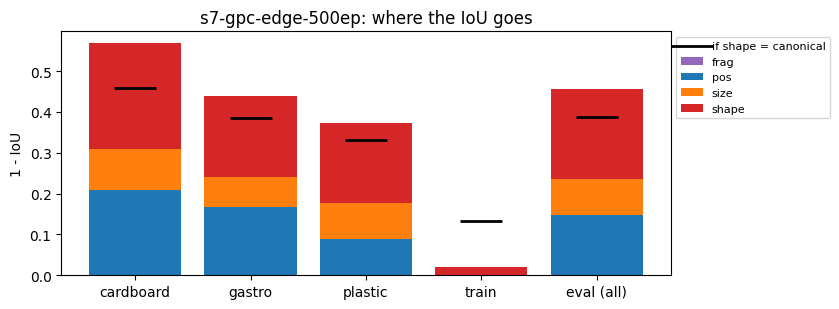

,loss_frag,loss_pos,loss_size,loss_shape
cardboard,-0.000,0.210,0.098,0.261
gastro,0.001,0.166,0.074,0.198
plastic,0.000,0.088,0.089,0.195
train,0.000,-0.000,0.000,0.020
eval (all),0.000,0.147,0.089,0.219


In [5]:
groups = list(summary.index)
LC = ["loss_frag", "loss_pos", "loss_size", "loss_shape"]
L = pd.concat([S.groupby("group")[LC].mean(),
               S[S.group != "train"][LC].mean().to_frame("eval (all)").T]).loc[groups]
fig, ax = plt.subplots(figsize=(8.5, 3.2))
bottom = np.zeros(len(L))
for c, col in zip(L.columns, ["tab:purple", "tab:blue", "tab:orange", "tab:red"]):
    ax.bar(groups, L[c], bottom=bottom, color=col, label=c.replace("loss_", "")); bottom += L[c].to_numpy()
ax.scatter(groups, (L.loss_frag + L.loss_pos + L.loss_size + 1 - summary.canon.loc[groups]).to_numpy(), marker="_", s=900, linewidths=2, c="k", label="if shape = canonical")
ax.set_ylabel("1 - IoU"); ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1, 1)); ax.set_title(f"{RUN}: where the IoU goes"); plt.tight_layout(); plt.show()
L.round(3)

## 4.3 Per Split (Eval)

Sorted by `iou_raw`. `shape_vs_canon = iou_size - canon`: below 0 means the model's shape, *even after fixing its position and size*, is worse than pasting the object's usual shape.

In [6]:
E = S[S.group != "train"]
per = E.groupby("split")[["multi_blob", "iou_raw", "iou_main", "iou_pos", "iou_size", "canon", "disk", "biou_aligned", "canon_biou", "com_err_px", "area_ratio"]].mean()
per.insert(0, "n", E.groupby("split").size())
per["shape_vs_canon"] = per.iou_size - per.canon
per.sort_values("iou_raw").round(3)

,n,multi_blob,iou_raw,iou_main,iou_pos,iou_size,canon,disk,biou_aligned,canon_biou,com_err_px,area_ratio,shape_vs_canon
split,,,,,,,,,,,,,
cardboard/cylinder-100g,4,0.000,0.000,0.000,0.569,0.561,0.650,0.850,0.561,0.650,11.800,0.812,-0.089
cardboard/vase-laser-shifted-3,31,0.032,0.000,0.000,0.277,0.644,0.913,0.811,0.371,0.772,29.668,0.277,-0.269
cardboard/cylinder-200g,51,0.078,0.014,0.014,0.446,0.646,0.703,0.875,0.646,0.703,15.543,2.061,-0.057
plastic/cube-shifted-lasers-3-backside,13,0.077,0.016,0.016,0.329,0.571,0.853,0.887,0.471,0.796,15.244,0.450,-0.282
cardboard/cylinder-500g,18,0.056,0.031,0.031,0.657,0.679,0.844,0.773,0.668,0.842,6.142,0.925,-0.165
gastro/cylinder-100g,5,0.000,0.036,0.036,0.157,0.817,0.301,0.733,0.817,0.300,24.264,7.317,0.516
cardboard/vase-laser-shifted-4,15,0.000,0.046,0.046,0.235,0.656,0.878,0.795,0.368,0.693,22.981,0.235,-0.222
plastic/cylinder-100g,28,0.000,0.066,0.066,0.084,0.780,0.467,0.900,0.780,0.467,2.285,14.618,0.314
gastro/cylinder-500g,23,0.130,0.107,0.112,0.247,0.819,0.787,0.941,0.819,0.787,6.696,4.744,0.032


## 4.3b Single-Blob Predictions Only

The same decomposition restricted to eval samples whose prediction is one blob, so position and shape are not mixed up with fragments.

In [7]:
E1 = S[(S.group != "train") & ~S.multi_blob]
t = E1.groupby("group")[["iou_raw", "iou_pos", "iou_size", "disk", "canon", "biou_raw", "biou_aligned", "canon_biou"] + LC].mean()
t.insert(0, "n", E1.groupby("group").size()); t.round(3)

,n,iou_raw,iou_pos,iou_size,disk,canon,biou_raw,biou_aligned,canon_biou,loss_frag,loss_pos,loss_size,loss_shape
group,,,,,,,,,,,,,
cardboard,1346,0.436,0.647,0.741,0.724,0.850,0.253,0.551,0.716,0.0,0.211,0.094,0.259
gastro,812,0.566,0.732,0.804,0.782,0.858,0.398,0.682,0.763,0.0,0.166,0.072,0.196
plastic,1687,0.629,0.717,0.806,0.779,0.846,0.432,0.658,0.733,0.0,0.088,0.089,0.194


## 4.4 Distributions

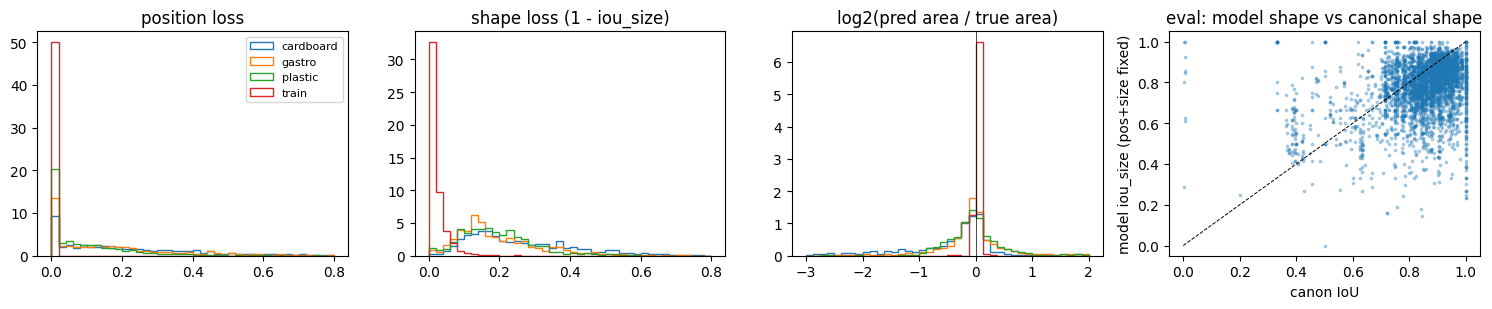

eval: fraction of samples where model shape beats canonical: 0.261
eval: median position loss 0.095, median shape loss 0.189


In [8]:
fig, axs = plt.subplots(1, 4, figsize=(15, 3.2))
for g, d in S.groupby("group"):
    axs[0].hist(d.loss_pos, bins=40, range=(0, .8), histtype="step", density=True, label=g)
    axs[1].hist(d.loss_shape, bins=40, range=(0, .8), histtype="step", density=True, label=g)
    axs[2].hist(np.log2(d.area_ratio), bins=40, range=(-3, 2), histtype="step", density=True, label=g)
axs[0].set_title("position loss"); axs[1].set_title("shape loss (1 - iou_size)"); axs[2].set_title("log2(pred area / true area)")
axs[2].axvline(0, c="k", lw=.5); axs[0].legend(fontsize=8)
axs[3].scatter(E.canon, E.iou_size, s=3, alpha=.3); axs[3].plot([0, 1], [0, 1], "k--", lw=.7)
axs[3].set_xlabel("canon IoU"); axs[3].set_ylabel("model iou_size (pos+size fixed)"); axs[3].set_title("eval: model shape vs canonical shape")
plt.tight_layout(); plt.show()
print("eval: fraction of samples where model shape beats canonical:", (E.iou_size > E.canon).mean().round(3))
print("eval: median position loss %.3f, median shape loss %.3f" % (E.loss_pos.median(), E.loss_shape.median()))

# 5 Samples

Columns: true mask, raw prediction (soft), prediction after position fix, after position + size fix, canonical shape. Green = true outline, red = predicted outline. Rows per box: worst position loss, two worst shape losses, median shape loss, best shape. All are eval samples.

========== cardboard ==========


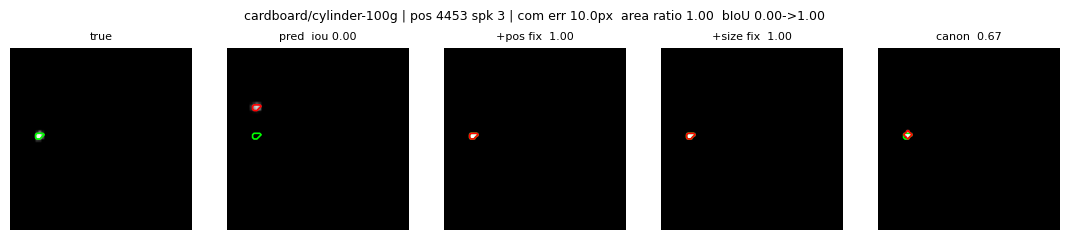

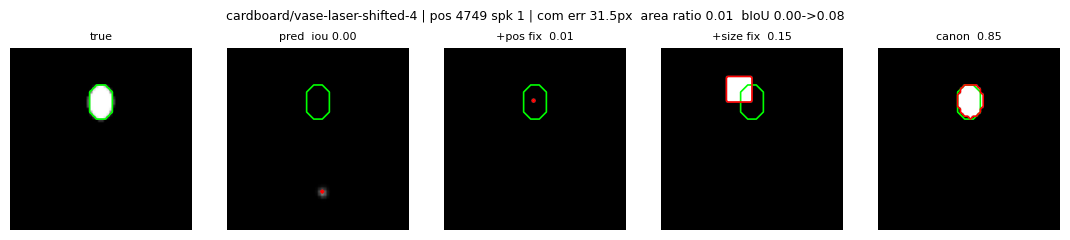

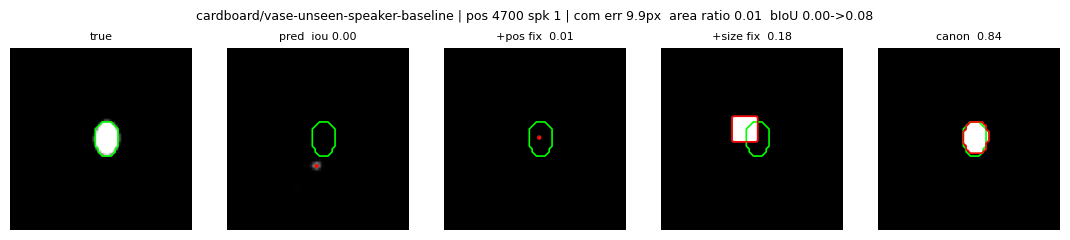

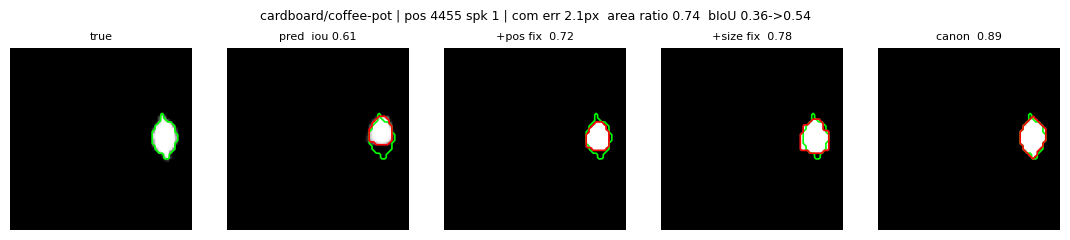

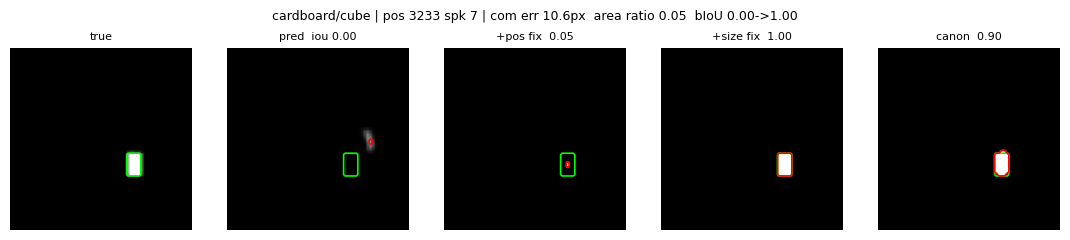

========== gastro ==========


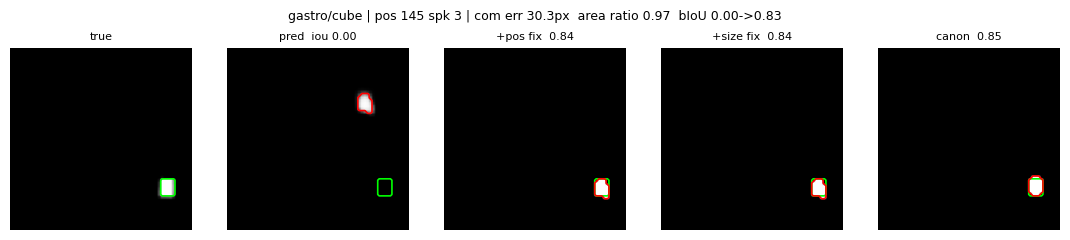

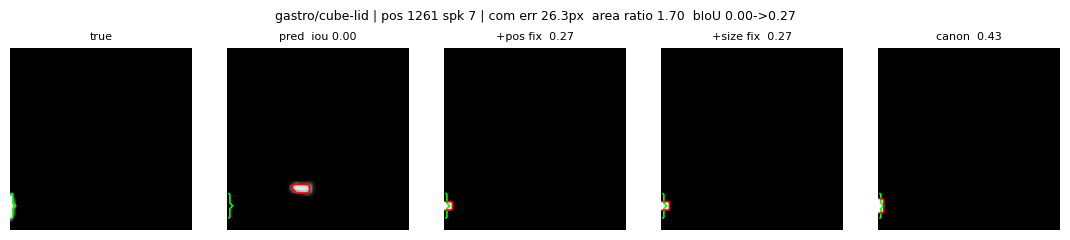

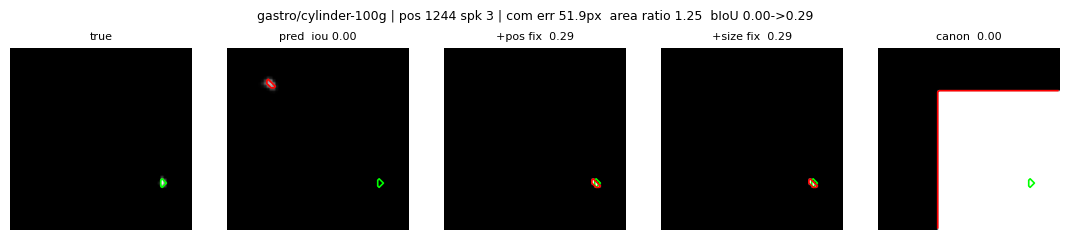

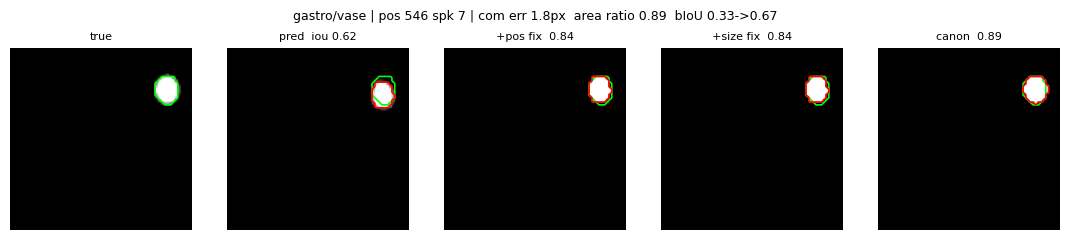

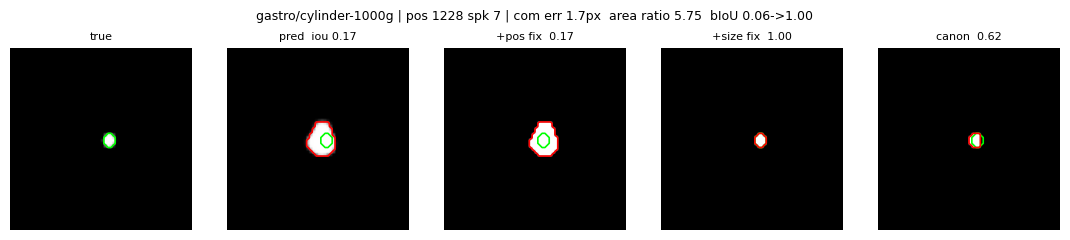

========== plastic ==========


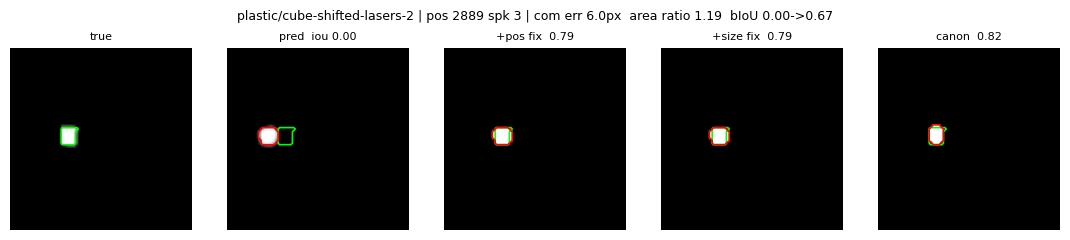

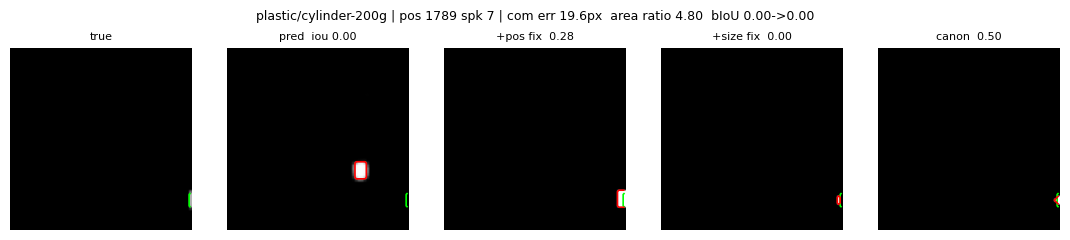

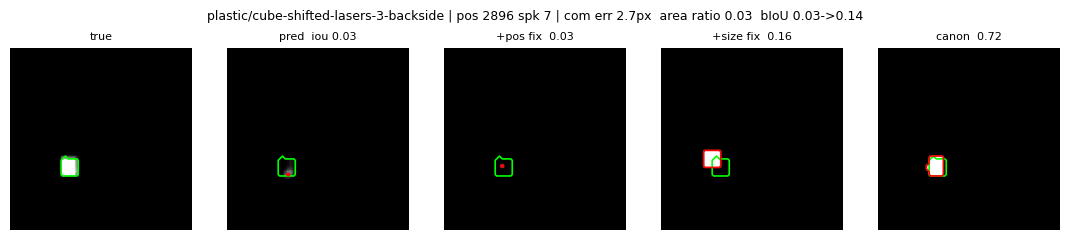

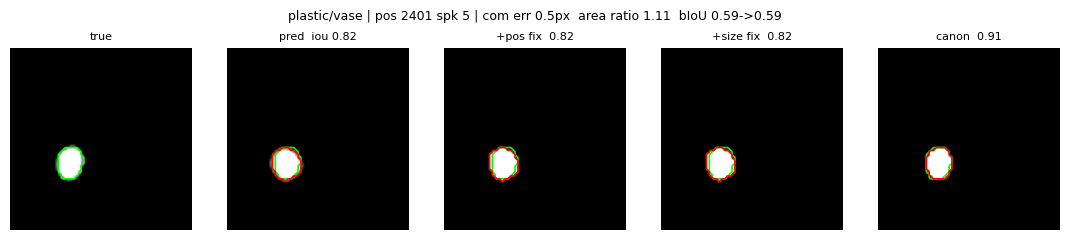

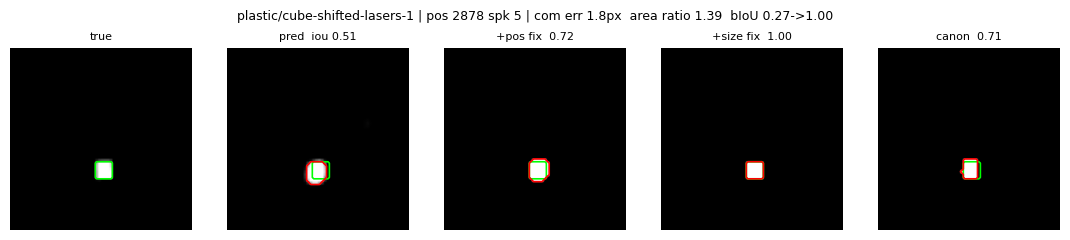

In [9]:
def outline(ax, m, c): ax.contour(m.astype(float), levels=[.5], colors=c, linewidths=1.2)

def show(r):
    i = int(r.i); p, g = Pb[i], Gb[i]; cg = com(g)
    lab = ndi.label(p)[0]; main = lab == 1 + np.argmax(np.bincount(lab.ravel())[1:]); cp = com(main)
    p_pos = shift(main, cg - cp); p_size = scale_about(p_pos, cg, np.sqrt(g.sum() / max(p_pos.sum(), 1))); k = canon(i, cg, g.sum())
    panels = [("true", G[i], None), (f"pred  iou {r.iou_raw:.2f}", P[i], p), (f"+pos fix  {r.iou_pos:.2f}", p_pos, p_pos),
              (f"+size fix  {r.iou_size:.2f}", p_size, p_size), (f"canon  {r.canon:.2f}", k if k is not None else g * 0, k)]
    fig, axs = plt.subplots(1, 5, figsize=(11, 2.4))
    for ax, (t, img, m) in zip(axs, panels):
        ax.imshow(img, cmap="gray", vmin=0, vmax=1); outline(ax, g, "lime")
        if m is not None: outline(ax, m, "red")
        ax.set_title(t, fontsize=8); ax.axis("off")
    fig.suptitle(f"{r.split} | pos {r.position_id} spk {r.speaker} | com err {r.com_err_px:.1f}px  area ratio {r.area_ratio:.2f}  bIoU {r.biou_raw:.2f}->{r.biou_aligned:.2f}", fontsize=9)
    plt.tight_layout(); plt.show()

for box, d in E.groupby("group"):
    print(f"========== {box} ==========")
    d = d.sort_values("loss_shape")
    picks = [d.loc[d.loss_pos.idxmax()], d.iloc[-1], d.iloc[-2], d.iloc[len(d) // 2], d.iloc[0]]
    for r in picks: show(r)

# 6 Two-Object Samples

A single CoM shift can't align two objects, so here the predicted mask is moved by the best integer shift within ±8 px (an upper bound on the position-fixed IoU).

In [10]:
def best_shift(p, g, R=8):
    pp = np.pad(p, R)
    return max(iou(pp[R + dy:R + dy + H, R + dx:R + dx + W], g) for dy in range(-R, R + 1) for dx in range(-R, R + 1))

rows = []
for i in np.flatnonzero((df.n_obj == 2).to_numpy()):
    p, g = Pb[i], Gb[i]
    if p.any(): rows.append(dict(i=i, iou_raw=iou(p, g), iou_best_shift=best_shift(p, g), area_ratio=p.sum() / g.sum(),
                                 n_pred_blobs=ndi.label(p)[1], n_true_blobs=ndi.label(g)[1]))
T = pd.DataFrame(rows).merge(df, left_on="i", right_index=True)
t = T.groupby("split")[["iou_raw", "iou_best_shift", "area_ratio", "n_pred_blobs", "n_true_blobs"]].mean()
t.insert(0, "n", T.groupby("split").size()); t.round(3)

,n,iou_raw,iou_best_shift,area_ratio,n_pred_blobs,n_true_blobs
split,,,,,,
cardboard/cube-vase,80,0.336,0.462,0.649,1.525,2.0
cardboard/two-cubes,72,0.097,0.238,0.343,1.417,2.0
gastro/cube-vase,30,0.215,0.299,0.518,1.667,2.0
gastro/two-cubes,41,0.219,0.392,0.702,1.585,2.0
plastic/cube-vase,39,0.373,0.426,0.528,1.795,2.0
plastic/two-cubes,64,0.390,0.484,0.843,1.766,2.0
train,334,0.977,0.977,1.001,2.000,2.0


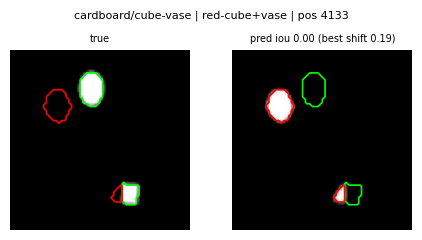

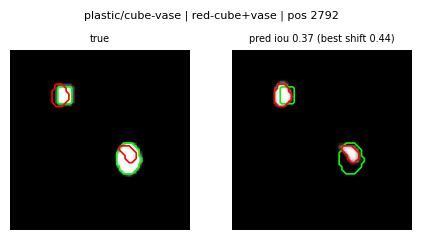

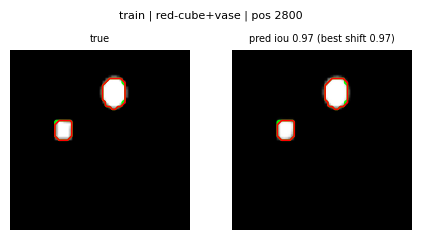

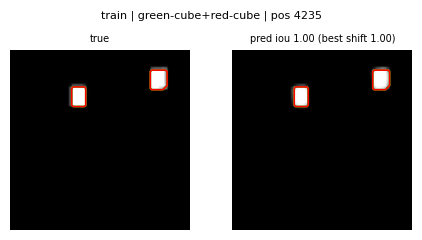

In [11]:
for _, r in T.sort_values("iou_raw").iloc[np.linspace(0, len(T) - 1, 4).astype(int)].iterrows():
    i = int(r.i)
    fig, axs = plt.subplots(1, 2, figsize=(4.6, 2.4))
    for ax, img, t in zip(axs, [G[i], P[i]], ["true", f"pred iou {r.iou_raw:.2f} (best shift {r.iou_best_shift:.2f})"]):
        ax.imshow(img, cmap="gray", vmin=0, vmax=1); outline(ax, Gb[i], "lime"); outline(ax, Pb[i], "red"); ax.set_title(t, fontsize=7); ax.axis("off")
    fig.suptitle(f"{r.split} | {r.object} | pos {r.position_id}", fontsize=8); plt.tight_layout(); plt.show()

# 7 Conclusions (s6-gastro-plastic-cardboard-3k, epoch 3000, single-object eval samples)

**Yes, shape is a real problem, but it is not the biggest one. Position is still the largest single lever.**

- **Where the missing IoU goes (eval mean IoU 0.51):** position 0.16, size 0.10, shape 0.23. Fragments (a spurious second blob) are about 0: only 2% of predictions have more than one blob.
- **Part of the shape term can't be removed.** The canonical-shape paste still leaves 0.15, from per-position perspective changes, mask noise and pixelation. The shape error **beyond** "paste the object's usual shape" is only about **0.08**, which is smaller than the position loss (0.16) and similar to the size loss (0.10).
- **Comparing the levers directly:** a perfect shape at the predicted CoM (`gt_at_pred_com`) lifts IoU from 0.51 to only **0.59**. Fixing just the position lifts it to **0.67**.
- **The model's shapes are no better than a disk.** Even with position and size fixed, the predicted shape scores 0.766 IoU. A plain disk of the right area scores 0.760, and the object's canonical shape scores 0.851. The model beats the canonical shape on only 23% of samples. Boundary IoU tells the same story: aligned 0.61 vs canonical 0.74. On held-out positions the model has learned essentially nothing about each object's outline; it paints roughly round blobs.
- **On train, everything is near-perfect:** IoU 0.996, shape loss 0.004. The model can represent shape; it just doesn't generalise it. A boundary loss or edge head only adds training signal, and train loss is already about 0. So these may help less than hoped unless they act as a regulariser. They should be tested against the canonical-shape ceiling.
- **Size: the model under-paints.** The median predicted/true area ratio is 0.89 (cardboard 0.82). The mean is above 1 only because of a long tail of overly large blobs.
- **Cardboard is the outlier.** It has 22% empty predictions (393 of 1822, excluded from the decomposition), a CoM error of 4.6 px vs about 2 px elsewhere, and the largest loss in every bucket.
- **Two-object samples:** IoU 0.14-0.36. The best ±8 px shift adds only about 0.1, and the predicted area is about half the true area. The second object is often missed or merged rather than misplaced.

**Implications**
1. The cheapest shape win is a **canonical-shape prior**: predict the object class (the head already exists), then paste or blend its canonical mask at the predicted CoM, scaled to the predicted area. Its ceiling here is +0.08 IoU over the current shapes.
2. Position and the empty-prediction problem (mostly cardboard) are worth more than shape.
3. When testing boundary loss or an edge head, log Boundary IoU and compare `iou_size` against `canon` with this notebook (`RUN=<run> jupyter execute ...`).